# 01 · Quickstart: where does the water pumped by this well come from?

A supply well pumps 800 m³/d from an unconfined aquifer next to a river. Before you can protect that supply you need to know **which part of the aquifer feeds it, and from which sources**: rainfall recharge on the land above, regional groundwater flowing in from upland, or river water drawn through the riverbed.

This tutorial answers that question with `gwsource` on a small MODFLOW 6 model. You will:

1. build and run the model (a few lines, using the shared tutorial helpers);
2. read one time step of its flows;
3. select the well as the *destination*;
4. trace backward from the well to get, for every cell, the **fraction through** $F$: the fraction of the water passing through the cell that ends up in the well;
5. map the capture zone with the $F = 0.1$ and $F = 0.5$ contours and learn what each one means;
6. map the **volume through** and **volume from**, and split the pumped water by source (recharge, river, model boundary);
7. check that the split adds up to the pumping rate;
8. compare $F$ with MODFLOW 6 particle tracking on the same flow field;
9. export the results to `.npz` and netCDF.

**Runtime:** about 4 seconds (the last cell prints the measured time). **Prerequisites:** the `gw-source` environment and `bin/mf6` (see the [tutorial README](../README.md)).

## Settings

All settings live in this first cell; later cells use only these names and what earlier cells return. The model workspace goes to `tutorials/_work/01_quickstart/`, which is git-ignored and recreated on every run. The shared model builders and plotting helpers live in [`tutorials/herebedragons.py`](../herebedragons.py).

In [1]:
import sys
import time
from pathlib import Path

import flopy
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.colors import LogNorm

sys.path.insert(0, str(Path.cwd().parent))  # tutorials/ holds the shared helpers
import herebedragons as hbd  # noqa: E402

import gwsource as gs  # noqa: E402
from gwsource import PrtConfig, track_particles  # noqa: E402

WORK = hbd.work_dir("01_quickstart", clean=True)  # tutorials/_work/01_quickstart (git-ignored)
MF6 = hbd.mf6_exe()  # <repo>/bin/mf6
WELL = "supply_well"  # boundname of the well we trace
THRESHOLDS = (0.1, 0.5)  # capture-zone contours of the fraction through (zones are F > t)
POROSITY = 0.3  # effective porosity (-) for MF6 PRT; it sets particle speeds, not paths
EDGE = (0.05, 0.95)  # F range of the capture-zone edge cells in the particle check
SOURCE_LABELS = {
    "RCH": "recharge", "RIV": "river leakage", "CHD": "west edge (regional inflow)", "WEL": "supply well"
}

START = time.perf_counter()  # for the runtime printed in the last cell


def km2(area_m2: float) -> str:
    """Return an area in km2 as text, rounded half up to 3 decimals (1,142,500 m2 -> 1.143)."""
    return f"{np.floor(area_m2 / 1e3 + 0.5) / 1e3:.3f}"


plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.0, 5.5)})
print(f"gwsource {gs.__version__}, FloPy {flopy.__version__}")

gwsource 0.0.1, FloPy 3.12.0.dev0


## 1. Build and run the model

The model is a single unconfined layer, 2 km × 2 km in 50 m cells:

- **recharge** of 0.5 mm/d (about 180 mm/yr) falls on every cell;
- the **west edge** is a constant head of 10 m, standing in for regional groundwater flowing in from upland;
- a **river** runs north–south at x ≈ 1.5 km with a stage of 6 m; its reaches carry the boundnames `river_north` and `river_south`;
- the **supply well** pumps 800 m³/d, 100 m west of the river.

Rows and columns in the text are counted from 1, starting at the north-west corner.

Groundwater flows from the west edge towards the river. Near the well the pumping lowers the water table below the river stage, so the river loses water to the aquifer there.

`hbd.build_quickstart` writes the MF6 input with FloPy, runs MF6 and returns the paths `gwsource` needs. Every builder in the helper module switches on the outputs that tracing requires: `SAVE_FLOWS` on every package, `BUDGET SAVE` in OC, and the binary grid file (`.grb`).

In [2]:
run = hbd.build_quickstart(WORK / "model", MF6)
spec = run.spec
print(f"{spec.nrow} rows x {spec.ncol} columns of {spec.delr:.0f} m, K = {spec.k} m/d")
for name, (row, col), rate in spec.wells:  # spec stores 0-based (row, col)
    print(f"well {name!r} in row {row + 1}, column {col + 1}: {rate:.0f} m3/d")
print(f"river in column {spec.riv_col + 1}")
print("output files:", ", ".join(p.name for p in (run.grb_file, run.budget_file, run.head_file)))

40 rows x 40 columns of 50 m, K = 5.0 m/d
well 'supply_well' in row 21, column 29: -800 m3/d
river in column 31
output files: quickstart.dis.grb, quickstart.cbc, quickstart.hds


## 2. Read one time step

`gs.read_step` reads the binary grid file and one time step of the budget file into a `FlowStep`: the cell connections, the flow across every connection (FLOW-JA-FACE) and every external term (each well, river reach, recharge cell or constant head) with its package. The model is steady, so there is a single step, `kstpkper=(0, 0)`. With `boundnames=True` the boundnames are read from the package input, so we can select the well by name.

The water budget below is built from those external terms: positive flows enter the aquifer, negative flows leave it.

In [3]:
step = gs.read_step(run.ws, boundnames=True)
print(f"grid {step.grid_type} {step.grid_shape}, {step.n_cells} cells, {step.n_terms} external terms")

rows = {}
for index, name in enumerate(step.package_names):
    q = step.term_flow[step.term_package == index]
    rows[SOURCE_LABELS.get(name, name)] = {"in (m3/d)": q[q > 0].sum(), "out (m3/d)": 0.0 - q[q < 0].sum()}
budget = pd.DataFrame(rows).T.round(1)
display(budget)
error = gs.diagnostics.budget_error(step)
print(f"model budget error: {error['relative']:.1e} of the total throughflow")

grid DIS (1, 40, 40), 1600 cells, 1681 external terms


,in (m3/d),out (m3/d)
supply well,0.0,800.0
river leakage,113.3,1587.2
recharge,1950.0,0.0
west edge (regional inflow),323.9,0.0


model budget error: 5.4e-11 of the total throughflow


The well takes 800 m³/d. Recharge (1950 m³/d; MF6 applies none to the constant-head cells) and the west edge (about 320 m³/d) bring water in. The river drains about 1590 m³/d, but the reaches next to the well *lose* about 110 m³/d to the aquifer. Which of these inflows end up in the well cannot be read from the budget; that is what the trace is for.

The head map shows the regional gradient from west to east and the cone of depression around the well, which pulls the water table below the river stage nearby.

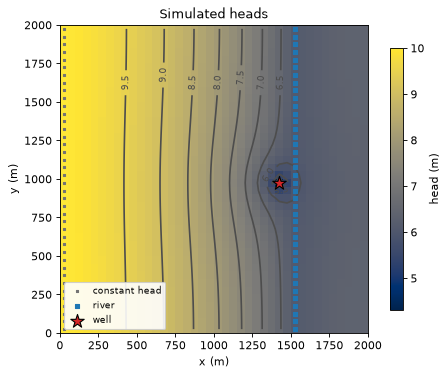

In [4]:
heads = flopy.utils.HeadFile(str(run.head_file)).get_data().ravel()
ax = hbd.plot_cells(run.grb_file, step, heads, cmap="cividis", title="Simulated heads", label="head (m)")
hbd.add_contours(ax, run.grb_file, step, heads, np.arange(5.0, 10.5, 0.5), colors="0.3", fmt="%.1f")
plt.show()

## 3. Select the well

A **selection** picks external terms: by package (`package="WEL"`), by bound number, by boundname, by cell or by zone. Here we pick the well by its boundname. A selection holds a boolean mask over the external terms and a mask of the cells they sit in.

In [5]:
well = gs.select(step, boundnames=[WELL])
well_cell = int(np.flatnonzero(well.cells)[0])
print(f"{well.terms.sum()} term selected, in cell {well_cell}: {step.term_flow[well.terms][0]:.1f} m3/d")

1 term selected, in cell 828: -800.0 m3/d


## 4. Trace backward from the well

`gwsource` assumes that each cell is **fully mixed**: whatever way the water came in, it leaves through each outflow (to a neighbour, or out of the model through a well, river or boundary) in proportion to the flows. For cell $i$ with total outflow $O_i$, a flow $q_{ij}$ to neighbour $j$ and a flow $d_i$ into the well, the fraction through obeys

$$
F_i = \sum_j \frac{q_{ij}}{O_i}\,F_j + \frac{d_i}{O_i}
\qquad\Longleftrightarrow\qquad
(\mathbf I - \mathbf P)\,\mathbf F = \mathbf S\,\mathbf D ,
$$

one sparse linear system for all cells at once. This is the cell-mixing method of Foley & Black (2013) and Black & Foley (2013), solved exactly. Tutorial 02 explains the equations in more detail. When the flow graph has no loops (as here) the solver uses a fast topological substitution; otherwise a sparse LU (tutorial 04).

`gs.backward` takes a dictionary of destination groups; a group can hold many terms (all wells of a well field, say), and any number of groups are solved together.

In [6]:
res = gs.backward(step, {WELL: well})
F = res.fraction_through[WELL]  # one value per cell
print("solver:", res.solver_used[0])
print(f"water entering the destination: {res.destination_inflow[WELL]:.1f} m3/d")
print(f"F in the well cell: {F[well_cell]:.3f}")

solver: topological
water entering the destination: 800.0 m3/d
F in the well cell: 1.000


## 5. The capture zone: fraction through

$F$ is 1 where all the water passing through a cell reaches the well. It is 0 where none does. In between, the water is split between the well and other outlets. The map below shows $F$ with the $F = 0.1$ and $F = 0.5$ contours.

The advice below on reading the two contours comes from the dispersion study of this package ([`docs/dispersion_study.md`](../../docs/dispersion_study.md)). That study compared $F$ with analytical and particle-tracked capture zones on two test problems: a well in regional flow, and a zone fed by recharge.

- **The zone F > 0.5** is the best estimate of the *advective* capture zone, the area a particle tracker would draw. Full mixing smears the zone edge over a band of intermediate values. The 0.5 contour sits near the middle of that band. In the study, its area was within 5 % of the reference zone for cells of 50 m or less.
- **The zone F > 0.1** is a *conservative* outline. It contained the whole reference zone in every test of the study. The cost is a larger area. It was 8 to 16 % larger than the reference zone on the recharge-fed problem, and 30 to 90 % larger for the well in regional flow.

The band between the two contours is wider on coarse grids. It narrows only slowly as the grid is refined. Choose the threshold for the purpose. A protection zone usually wants the conservative one.

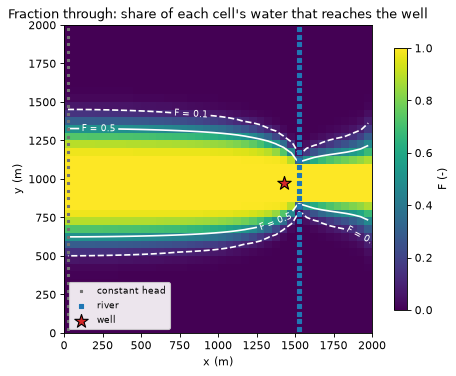

In [7]:
ax = hbd.plot_cells(
    run.grb_file, step, F, cmap="viridis", vmin=0.0, vmax=1.0,
    title="Fraction through: share of each cell's water that reaches the well", label="F (-)",
)
hbd.add_contours(ax, run.grb_file, step, F, THRESHOLDS, colors="w", linestyles=["--", "-"])
plt.show()

The capture zone reaches back to the west edge: upgradient of the well, the water comes from recharge and from the regional inflow. Two features deserve a comment.

- **The narrow tail east of the river.** In this single-layer model the river cells are *weak sinks*: they drain only part of the water that flows through them, and the rest flows on. Under full mixing, water arriving from the east is mixed with the river leakage in the river cell, and part of the mixture continues to the well. In a real aquifer some of that water would pass under the river; with one layer the model cannot say. Tutorial 02 discusses weak sinks.
- **The smeared edge.** The band between the two contours is a few cells wide; that is the numerical dispersion of full mixing discussed above, not a property of the aquifer.

$F = 1$ in the well cell itself: the well takes more water than flows into its cell from the neighbours, so it is a *strong* sink that captures all of that cell's water.

The area of each zone, and the threshold-free area $\sum_i F_i A_i$ (areas in km², rounded to three decimals):

In [8]:
area = step.area
zones = {f"F > {t}": F > t for t in THRESHOLDS}
zone_table = pd.DataFrame({
    "cells": {name: int(inside.sum()) for name, inside in zones.items()},
    "area (km2)": {name: km2(area[inside].sum()) for name, inside in zones.items()},
})
zone_table.loc["sum of F x cell area"] = ["", km2(float(F @ area))]
display(zone_table)

,cells,area (km2)
F > 0.1,630,1.575
F > 0.5,457,1.143
sum of F x cell area,,1.173


## 6. Volume through and volume from

$F$ says *what share* of a cell's water reaches the well; it does not say *how much* water that is. Two more outputs give volumes (m³/d):

- **Volume through**, $F_i\,O_i$: how much of the water flowing through cell $i$ reaches the well. It traces the main flow paths into the well and rises to the full pumping rate at the well.
- **Volume from**, $F_i\,q_{i,k}$ for each source term $k$ of the cell (recharge, river leakage, boundary inflow): how much of the water *entering the model* in cell $i$ reaches the well. Summed over all cells, it is the pumping rate.

The colour scales are logarithmic; values below the bottom of the scale take its lightest colour. The blue line is the $F = 0.5$ contour.

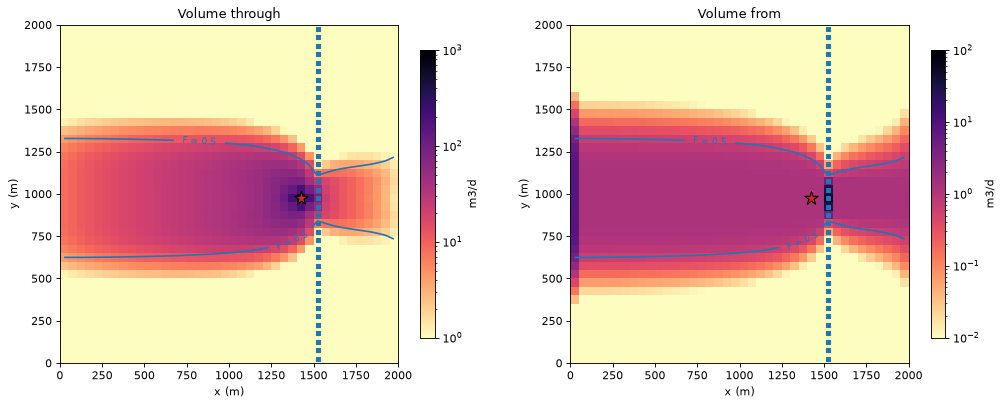

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13.0, 5.0))
hbd.plot_cells(
    run.grb_file, step, res.volume_through[WELL], ax=axes[0], cmap="magma_r",
    norm=LogNorm(1.0, 1000.0), title="Volume through", label="m3/d", overlay=False,
)
hbd.plot_cells(
    run.grb_file, step, res.volume_from[WELL], ax=axes[1], cmap="magma_r",
    norm=LogNorm(0.01, 100.0), title="Volume from", label="m3/d", overlay=False,
)
for ax in axes:
    hbd.add_contours(ax, run.grb_file, step, F, (0.5,), colors="tab:blue")
    hbd.overlay_features(ax, run.grb_file, step, packages=("RIV", "WEL"), legend=False)
fig.tight_layout()
plt.show()

The volume-from map has three kinds of contributing cells: every recharge cell inside the capture zone contributes up to 1.25 m³/d (its recharge times $F$), the constant-head cells on the west edge contribute their regional inflow, and a few river cells next to the well contribute river leakage, with much larger volumes from a small area.

### The well's water by source

`volume_from_by_term` splits volume from by the package of each source term. Summing each package's map gives the well's water by source; `hbd.volume_from_table` does this and adds each source's share.

,volume_from,share
recharge,568.6,0.711
west edge (regional inflow),118.1,0.148
river leakage,113.3,0.142


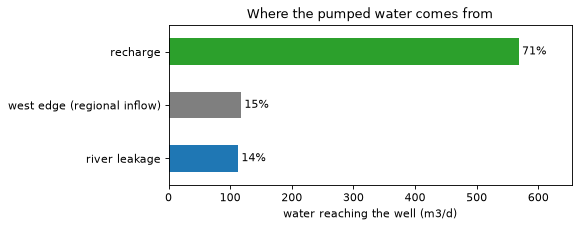

In [10]:
by_source = hbd.volume_from_table(res, WELL)
by_source.index = [SOURCE_LABELS.get(name, name) for name in by_source.index]
display(by_source.round({"volume_from": 1, "share": 3}))

ax = by_source["volume_from"].plot.barh(color=["tab:green", "tab:gray", "tab:blue"], figsize=(6.5, 2.6))
ax.invert_yaxis()
ax.set_xlabel("water reaching the well (m3/d)")
ax.set_title("Where the pumped water comes from")
for y, (volume, share) in enumerate(by_source[["volume_from", "share"]].to_numpy()):
    ax.text(volume + 5.0, y, f"{share:.0%}", va="center")
ax.set_xlim(0.0, 1.15 * by_source["volume_from"].max())
plt.show()

About 70 % of the pumped water is recharge that fell inside the capture zone, and the rest splits roughly equally between regional inflow from the west and water drawn from the river. The river leakage in the well (113 m³/d) equals all the leakage in the model budget above: every losing river reach lies inside the capture zone. The river share is what a water-quality assessment of riverbank filtration would ask for.

## 7. Sanity check: the sources add up to the pumping rate

Every unit of water that leaves through the well entered the model somewhere. So the volume from, summed over all cells and sources, must equal the well's pumping rate. The identity is exact up to the model's own budget residual $r_i$ (MF6's convergence error):

$$
\sum_i F_i\,\mathrm{Src}_i \;-\; \sum_i F_i\, r_i \;=\; Q_\text{well} .
$$

In [11]:
check = gs.diagnostics.backward_closure(step, res, WELL)
print(f"sum of volume from:        {check.lhs:10.4f} m3/d")
print(f"pumping rate:              {check.rhs:10.4f} m3/d")
print(f"residual term sum(F r):    {check.residual_term:10.2e} m3/d")
print(f"relative closure error:    {check.relative_error:10.1e}")
assert check.relative_error < 1e-8

sum of volume from:          800.0000 m3/d
pumping rate:                800.0000 m3/d
residual term sum(F r):      7.22e-07 m3/d
relative closure error:       0.0e+00


The closure follows from the trace equations themselves. It catches errors in the computation and in the model budget. It cannot show whether full mixing puts the capture zone in the right place. The next section compares with a method that does not mix.

## 8. An independent check: MODFLOW 6 particle tracking

MODFLOW 6 particle tracking (PRT) follows water by advection alone, on the same flow field. `track_particles` writes and runs a PRT model for the well (tutorial 06 explains it in detail):

- particles start from every source term (recharge, river leakage, inflow at the west edge) in the cells with $F > 0$, spread over each cell;
- each particle carries its share of the source flow as a weight, so sums over particles are flow-weighted;
- where a particle passes a cell with another sink, such as a gaining river cell, it loses the share of its weight that this sink removes. These weight-losing particles keep the particle totals consistent with the water budget.

For each release cell, the **captured fraction** $P$ is the weight that reaches the well divided by the weight released there. It is the particle counterpart of $F$. The particle capture zone is the set of cells where $P > 0.5$, that is, where most of the water released reaches the well. Porosity changes how fast the particles move, not where they go, so it does not change $P$.

In [12]:
start = time.perf_counter()
prt = track_particles(run.ws, step, res, WELL, PrtConfig(porosity=POROSITY), MF6, WORK / "prt")
P = prt.cell_capture_fraction  # flow-weighted captured fraction per release cell (NaN: none released)
released = np.isfinite(P)
edge = released & (F > EDGE[0]) & (F < EDGE[1])
print(f"{prt.release.n} particles from {released.sum()} cells, run in {time.perf_counter() - start:.1f} s")
print(f"particle flow reaching the well: {prt.captured_flow:.1f} of {res.destination_inflow[WELL]:.1f} m3/d")
print(f"mean |P - F|: {np.abs(P - F)[released].mean():.3f} over all {released.sum()} release cells, "
      f"{np.abs(P - F)[edge].mean():.3f} over the {edge.sum()} edge cells ({EDGE[0]} < F < {EDGE[1]})")

particle_zone = np.nan_to_num(P) > 0.5
with_particles = {**zones, "particles, P > 0.5": particle_zone}
particle_area = area[particle_zone].sum()
compare = pd.DataFrame({
    "cells": {name: int(inside.sum()) for name, inside in with_particles.items()},
    "area (km2)": {name: km2(area[inside].sum()) for name, inside in with_particles.items()},
    "vs particle area": {name: f"{area[inside].sum() / particle_area - 1.0:+.1%}" for name, inside in with_particles.items()},
    "particle-zone cells outside": {name: int((particle_zone & ~inside).sum()) for name, inside in with_particles.items()},
})
display(compare)

18208 particles from 1133 cells, run in 3.0 s
particle flow reaching the well: 799.9 of 800.0 m3/d
mean |P - F|: 0.058 over all 1133 release cells, 0.164 over the 372 edge cells (0.05 < F < 0.95)


,cells,area (km2),vs particle area,particle-zone cells outside
F > 0.1,630,1.575,+34.9%,0
F > 0.5,457,1.143,-2.1%,14
"particles, P > 0.5",467,1.168,+0.0%,0


The particles that reach the well carry 799.9 of the 800 m³/d pumped, so the release points resolve the sources well. Cell by cell, $ and $ differ by 0.058 on average over all release cells, and by 0.164 over the edge cells. At the edge a particle gives 0 or 1 for most of a cell's water, while full mixing gives an intermediate value.

The zone  > 0.5$ is 2.1 % smaller than the particle zone. The zone  > 0.1$ is 34.9 % larger and contains every cell of the particle zone. Both results agree with the guidance of section 5: the 35 % excess lies in the range the dispersion study found for a well in regional flow. This is one model on one grid, so it illustrates the guidance rather than proving it.

## 9. Export

`gs.export.save_npz` writes every output as an array on the model grid (keys `<output>__<group>` and `<output>__<group>__<package>` for the split by source), with inactive cells as NaN. `gs.export.to_netcdf` writes the same outputs to a self-describing netCDF file with units, long names and a provenance record (package version, model files, options), ready for xarray, QGIS or Panoply. `gs.export.to_geopackage` writes polygons for GIS (tutorial 04).

In [13]:
npz_path = gs.export.save_npz(WORK / f"{WELL}.npz", step, res)
with np.load(npz_path) as data:
    print(f"{npz_path.name}: {len(data.files)} arrays, e.g.", ", ".join(sorted(data.files)[:4]))

nc_path = gs.export.to_netcdf(WORK / f"{WELL}.nc", step, res)
with xr.open_dataset(nc_path) as ds:
    print(f"{nc_path.name}: variables", ", ".join(ds.data_vars))
    f_nc = ds["fraction_through"].sel(group=WELL)
    print("fraction_through dims:", f_nc.dims, "| units:", f_nc.attrs["units"])
    assert np.allclose(f_nc.values.ravel(), F)

supply_well.npz: 13 arrays, e.g. active, area, cycle_id, flux_from__supply_well


supply_well.nc: variables active, area, fraction_through, volume_through, flux_through, volume_from, fraction_from_cell_input, fraction_from_total, flux_from, volume_from_by_term, destination_inflow, cycle_id
fraction_through dims: ('layer', 'row', 'col') | units: 1


In [14]:
print(f"runtime: {time.perf_counter() - START:.0f} s")

runtime: 4 s


## Key points

- A backward trace answers "where does the water reaching this destination come from?" for every cell at once, from the flows MF6 already saves (`SAVE_FLOWS`, the budget file and the binary grid file).
- **Fraction through** $F$ is the share of a cell's water that reaches the destination. Under full mixing the capture-zone edge is smeared: use the zone $F > 0.5$ as the best estimate of the advective zone and a low threshold such as $F > 0.1$ for a conservative outline ([`docs/dispersion_study.md`](../../docs/dispersion_study.md)).
- **Volume through** shows the flow paths and how much water they carry; **volume from** shows where the destination's water enters the model, and its split by package gives the shares by source.
- The volume from sums to the destination inflow (here the pumping rate) up to the model's own budget residual. Check it. This closure is an internal identity of the method, not an independent test.
- MF6 particle tracking on the same flow field is an independent check. Here the zone $F > 0.5$ is close to the particle zone, and the zone $F > 0.1$ contains it.
- Results export to `.npz`, netCDF and GeoPackage.

## Next

[02 · Accounting](../02_accounting/02_accounting.ipynb): what full mixing means, gross vs net accounting, weak sinks, the Foley & Black (2013) worked example, and the diagnostics that keep the results honest.